# Stock Market: Out-of-Time Share Price Extrapolation

Downloads the Kaggle stock market dataset, builds lag/rolling features, trains Decision Tree, Random Forest and KNN regressors on the earliest 80% of the timeline, and tests them on the latest 20%.

In [2]:
# Run once. Safe to skip if everything is already installed.
%pip install -q kagglehub pandas numpy matplotlib scikit-learn ipython

Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jasineri/stock-market-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\prajval gupta\.cache\kagglehub\datasets\jasineri\stock-market-dataset\versions\1047


## 1. Load the raw files

In [5]:
DATA_DIR = Path(path)
SUPPORTED = {".csv", ".parquet", ".json", ".xlsx"}

files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in SUPPORTED)
if not files:
    raise FileNotFoundError(f"No data files found under {DATA_DIR}")


def read_any(p):
    ext = p.suffix.lower()
    if ext == ".csv":
        return pd.read_csv(p, low_memory=False)
    if ext == ".parquet":
        return pd.read_parquet(p)
    if ext == ".json":
        return pd.read_json(p)
    return pd.read_excel(p)


tables = {}
for p in files:
    tables[p.name] = read_any(p)
    print(f"{p.name}: {tables[p.name].shape[0]:,} rows x {tables[p.name].shape[1]} columns")
    display(tables[p.name].head(3))

# The biggest table is treated as the price history
main_name = max(tables, key=lambda k: len(tables[k]))
df_raw = tables[main_name]
print("\nUsing", main_name, "as the main price table")

share.csv: 671,003 rows x 3 columns


,ID,TS,PRICE
0,7,2026-09-15 07:30:01,177
1,13,2026-09-15 07:30:20,664
2,27,2026-09-15 07:31:47,880


share_lookup.csv: 1,019 rows x 2 columns


,ID,ISIN
0,1,AN8068571086
1,984,AT0000652011
2,619,AT0000743059


share_trade.csv: 126,769 rows x 6 columns


,TS,MS,ISIN,ACTION,VOL,DATA
0,2026-01-02 09:50:32,12,DE0005158703,BUY,-2201.20,"{name=Bechtle,quantity=50,source=}"
1,2026-01-02 12:42:32,653,NL0013654783,SELL,5.79,"{name=Prosus,quantity=5,source=HL}"
2,2026-01-02 14:42:31,581,US5951121038,SELL,41.74,"{name=Micron Technology,quantity=2,source=HL}"



Using share.csv as the main price table


## 2. Build `df_ml`: timestamps, target and features

The column names are auto-detected. If the printout below shows a wrong pick, set `ID_COL`, `TS_COL` or `PRICE_COL` by hand and re-run this cell. Features are built only from **earlier** rows of each stock, so the target `PRICE_curr` never leaks into its own inputs.

In [6]:
# ---- Override these only if auto-detection picks the wrong column ----
ID_COL = None      # e.g. "ID"
TS_COL = None      # e.g. "TS"
PRICE_COL = None   # e.g. "PRICE"
EXTRA_FEATURES = []  # other numeric columns you want to use as inputs, e.g. ["VOLUME"]


def pick(columns, exact, contains):
    lowered = {c.lower(): c for c in columns}
    for name in exact:
        if name in lowered:
            return lowered[name]
    for c in columns:
        if any(k in c.lower() for k in contains):
            return c
    return None


cols = list(df_raw.columns)
ID_COL = ID_COL or pick(cols, ["id", "isin", "ticker", "symbol"], ["isin", "ticker", "symbol", "instrument", "security"])
TS_COL = TS_COL or pick(cols, ["ts_dt", "ts", "timestamp", "datetime", "date", "time"], ["timestamp", "date", "time"])
PRICE_COL = PRICE_COL or pick(cols, ["price_curr", "price", "close", "adj close", "adj_close"], ["price", "close"])

print("Columns found:", cols)
print(f"Using ID={ID_COL!r}, TS={TS_COL!r}, PRICE={PRICE_COL!r}")
if TS_COL is None or PRICE_COL is None:
    raise ValueError("Could not detect the timestamp/price columns. Set TS_COL and PRICE_COL above.")

df = df_raw.rename(columns={TS_COL: "TS", PRICE_COL: "PRICE_curr"}).copy()
if ID_COL is None:
    print("No ID-like column found: treating the data as one series.")
    df["ID"] = 0
elif ID_COL != "ID":
    df = df.rename(columns={ID_COL: "ID"})

# Timestamp -> datetime (handles epoch seconds/ms/us/ns or date strings)
if pd.api.types.is_numeric_dtype(df["TS"]):
    m = df["TS"].dropna().abs().median()
    unit = "s" if m < 1e11 else "ms" if m < 1e14 else "us" if m < 1e17 else "ns"
    df["TS_dt"] = pd.to_datetime(df["TS"], unit=unit, errors="coerce")
else:
    df["TS_dt"] = pd.to_datetime(df["TS"], errors="coerce")

df["PRICE_curr"] = pd.to_numeric(df["PRICE_curr"], errors="coerce")
df = df.dropna(subset=["ID", "TS_dt", "PRICE_curr"])
df = df.sort_values(["ID", "TS_dt"]).reset_index(drop=True)

# Lag, rolling and calendar features (all use only past prices)
by_id = df.groupby("ID")["PRICE_curr"]
for k in (1, 2, 3, 5):
    df[f"PRICE_lag{k}"] = by_id.shift(k)

prev = by_id.shift(1)
df["RETURN_1"] = (df["PRICE_lag1"] - df["PRICE_lag2"]) / df["PRICE_lag2"]
df["ROLL_MEAN_3"] = prev.groupby(df["ID"]).transform(lambda s: s.rolling(3).mean())
df["ROLL_MEAN_5"] = prev.groupby(df["ID"]).transform(lambda s: s.rolling(5).mean())
df["ROLL_STD_5"] = prev.groupby(df["ID"]).transform(lambda s: s.rolling(5).std())
df["DAY_OF_WEEK"] = df["TS_dt"].dt.dayofweek
df["MONTH"] = df["TS_dt"].dt.month

features = [
    "PRICE_lag1", "PRICE_lag2", "PRICE_lag3", "PRICE_lag5",
    "RETURN_1", "ROLL_MEAN_3", "ROLL_MEAN_5", "ROLL_STD_5",
    "DAY_OF_WEEK", "MONTH",
] + list(EXTRA_FEATURES)

df = df.replace([np.inf, -np.inf], np.nan)
df_ml = df.dropna(subset=features + ["PRICE_curr"]).reset_index(drop=True)
if df_ml.empty:
    raise ValueError("No rows left after feature building. Check ID_COL/TS_COL/PRICE_COL.")

print(f"\ndf_ml: {len(df_ml):,} rows, {df_ml['ID'].nunique():,} stocks, "
      f"{df_ml['TS_dt'].min()} to {df_ml['TS_dt'].max()}")
display(df_ml[["ID", "TS_dt", "PRICE_curr"] + features].head())

Columns found: ['ID', 'TS', 'PRICE']
Using ID='ID', TS='TS', PRICE='PRICE'

df_ml: 667,292 rows, 742 stocks, 2026-09-15 07:48:46 to 2026-10-20 22:57:40


,ID,TS_dt,PRICE_curr,PRICE_lag1,PRICE_lag2,PRICE_lag3,PRICE_lag5,RETURN_1,ROLL_MEAN_3,ROLL_MEAN_5,ROLL_STD_5,DAY_OF_WEEK,MONTH
0,1,2026-09-16 15:40:15,4619,4680.0,4677.0,4696.0,4613.0,0.000641,4684.333333,4672.6,34.529697,2,9
1,1,2026-09-16 16:00:14,4642,4619.0,4680.0,4677.0,4697.0,-0.013034,4658.666667,4673.8,31.948396,2,9
2,1,2026-09-16 17:04:14,4578,4642.0,4619.0,4680.0,4696.0,0.004979,4647.000000,4662.8,31.427695,2,9
3,1,2026-09-16 17:16:14,4592,4578.0,4642.0,4619.0,4677.0,-0.013787,4613.000000,4639.2,42.587557,2,9
4,1,2026-09-16 22:59:53,4560,4592.0,4578.0,4642.0,4680.0,0.003058,4604.000000,4622.2,40.647263,2,9


## 3. Chronological 80/20 split and model comparison

In [7]:
# Chronological 80/20 Split for Genuine Future Extrapolation
cutoff_ts = df_ml['TS_dt'].quantile(0.80)
train_df = df_ml[df_ml['TS_dt'] <= cutoff_ts]
test_df  = df_ml[df_ml['TS_dt'] > cutoff_ts].copy()

X_train, y_train = train_df[features], train_df['PRICE_curr']
X_test,  y_test  = test_df[features],  test_df['PRICE_curr']

# Scale features for KNN while keeping tree inputs direct
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

models = {
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=7, weights='distance', n_jobs=-1)
}

metrics_list = []
for name, model in models.items():
    if name == 'K-Nearest Neighbors':
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    test_df[f'Pred_{name}'] = preds
    metrics_list.append({
        'Model': name,
        'RMSE ($)': np.sqrt(mean_squared_error(y_test, preds)),
        'MAE ($)': mean_absolute_error(y_test, preds),
        'R2': r2_score(y_test, preds)
    })

results_df = pd.DataFrame(metrics_list)
display(results_df)

,Model,RMSE ($),MAE ($),R2
0,Decision Tree,6181.331976,158.857005,0.997926
1,Random Forest,2508.097656,76.333964,0.999659
2,K-Nearest Neighbors,3994.332778,457.080697,0.999134


In [8]:
# Sanity check: the plot below uses stock ID 842, so make sure it is in the test window
n_842 = int((test_df["ID"] == 842).sum())
print(f"Test rows for ID 842: {n_842}")
if n_842 == 0:
    print("ID 842 is not in the test set. Stocks with the most test rows:")
    print(test_df["ID"].value_counts().head(10))

Test rows for ID 842: 1314


## 4. Extrapolated vs. actual share prices

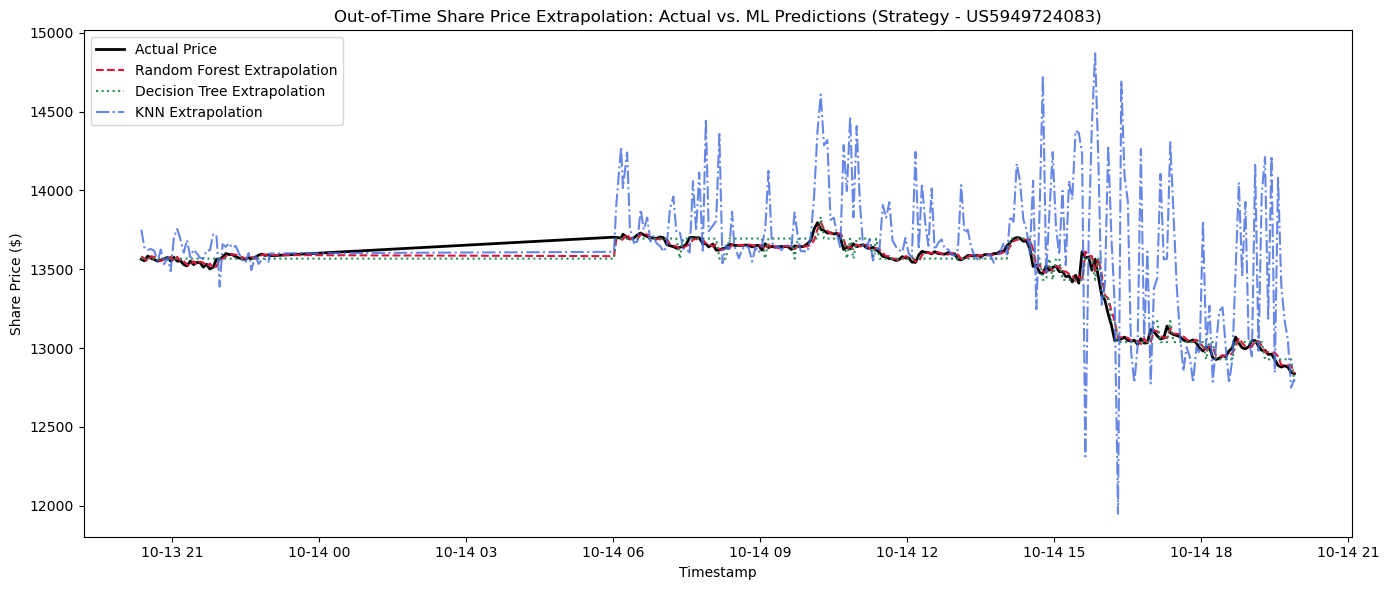

In [9]:
# ==========================================
# CELL 5: Visualizing Extrapolated vs. Actual Share Prices
# ==========================================
# Plot actual vs predicted trajectory for Strategy (ID=842) in the test window
sample_stock = test_df[test_df['ID'] == 842].head(250)

plt.figure(figsize=(14, 6))
plt.plot(sample_stock['TS_dt'], sample_stock['PRICE_curr'], label='Actual Price', color='black', linewidth=2)
plt.plot(sample_stock['TS_dt'], sample_stock['Pred_Random Forest'], label='Random Forest Extrapolation', linestyle='--', color='crimson')
plt.plot(sample_stock['TS_dt'], sample_stock['Pred_Decision Tree'], label='Decision Tree Extrapolation', linestyle=':', color='seagreen')
plt.plot(sample_stock['TS_dt'], sample_stock['Pred_K-Nearest Neighbors'], label='KNN Extrapolation', linestyle='-.', color='royalblue', alpha=0.8)
plt.title('Out-of-Time Share Price Extrapolation: Actual vs. ML Predictions (Strategy - US5949724083)')
plt.xlabel('Timestamp')
plt.ylabel('Share Price ($)')
plt.legend()
plt.tight_layout()
plt.show()